# Sprint 7 – Notebook 2: Machine Learning Workflow

## Objective
To understand and implement the complete Machine Learning workflow using Car Price Prediction .

1. Problem Definition

Explanation:

The objective of this project is to predict the selling price of a car based on its features, such as brand, manufacturing year, engine size, fuel type, transmission, mileage, condition, and model.

This is a supervised machine learning regression problem because the target variable, Price, contains continuous numerical values.

Target variable: Price

Problem type: Regression

Goal: Predict the estimated selling price of a car.

2. Business Understanding

Explanation:

Car price prediction helps buyers and sellers understand the estimated market value of a vehicle.
- Buyers can compare prices before purchasing a car.
- Sellers can estimate a reasonable selling price.
- Dealers can support their pricing decisions.
- Businesses can use predictions to understand car market trends.
Business objective: Develop a machine learning model that predicts car prices using available car information.

3. Data Collection

    Explanation:

    The car price dataset is provided in CSV format for this machine learning practice.
    - Dataset name: car_price_prediction_.csv
    - File location: Car_Dataset/
    - Number of records: 2,500
    - Original number of columns: 10
    - Target column: Price
    The dataset contains information about different cars, including their brand, year, engine size, fuel type, transmission, mileage, condition, price, and model.

4. Data Understanding

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

car_df = pd.read_csv(r"datasets/car_prediction/car_price_prediction_.csv")

print("Dataset Shape:", car_df.shape)
print("\nDataset Columns:")
print(car_df.columns.tolist())

print("\nFirst Five Records:")
display(car_df.head())

print("\nDataset Information:")
car_df.info()

print("\nStatistical Summary:")
display(car_df.describe())

Dataset Shape: (2500, 10)

Dataset Columns:
['Car ID', 'Brand', 'Year', 'Engine Size', 'Fuel Type', 'Transmission', 'Mileage', 'Condition', 'Price', 'Model']

First Five Records:


,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,26613.92,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,14679.61,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,44402.61,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,86374.33,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,73577.10,Mustang



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2500 non-null   int64  
 1   Brand         2500 non-null   object 
 2   Year          2500 non-null   int64  
 3   Engine Size   2500 non-null   float64
 4   Fuel Type     2500 non-null   object 
 5   Transmission  2500 non-null   object 
 6   Mileage       2500 non-null   int64  
 7   Condition     2500 non-null   object 
 8   Price         2500 non-null   float64
 9   Model         2500 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 195.4+ KB

Statistical Summary:


,Car ID,Year,Engine Size,Mileage,Price
count,2500.00000,2500.0000,2500.000000,2500.000000,2500.000000
mean,1250.50000,2011.6268,3.465240,149749.844800,52638.022532
std,721.83216,6.9917,1.432053,87919.952034,27295.833455
min,1.00000,2000.0000,1.000000,15.000000,5011.270000
25%,625.75000,2005.0000,2.200000,71831.500000,28908.485000
50%,1250.50000,2012.0000,3.400000,149085.000000,53485.240000
75%,1875.25000,2018.0000,4.700000,225990.500000,75838.532500
max,2500.00000,2023.0000,6.000000,299967.000000,99982.590000


Check missing values and duplicates

In [94]:
print("Missing Values:")
print(car_df.isnull().sum())

print("\nDuplicate Records:")
print(car_df.duplicated().sum())

Missing Values:
Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Mileage         0
Condition       0
Price           0
Model           0
dtype: int64

Duplicate Records:
0


Explanation:

Data understanding helps identify the structure, columns, data types, missing values, duplicate records, and statistical information in the dataset.

5. Exploratory Data Analysis (EDA)

A. Car price distribution

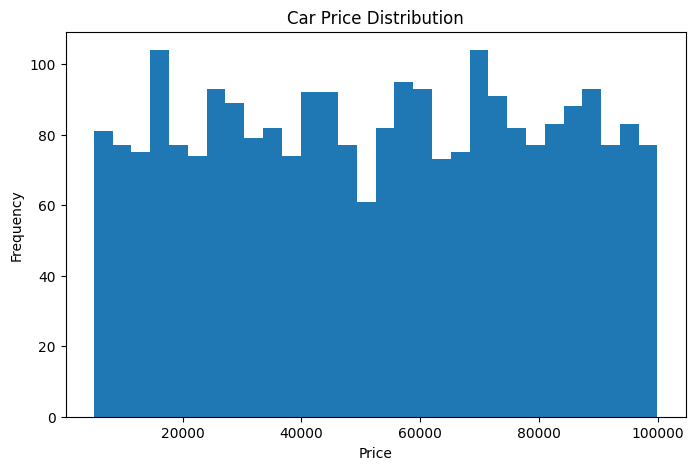

In [95]:
plt.figure(figsize=(8, 5))
plt.hist(car_df["Price"], bins=30)
plt.title("Car Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

B. Average price by brand

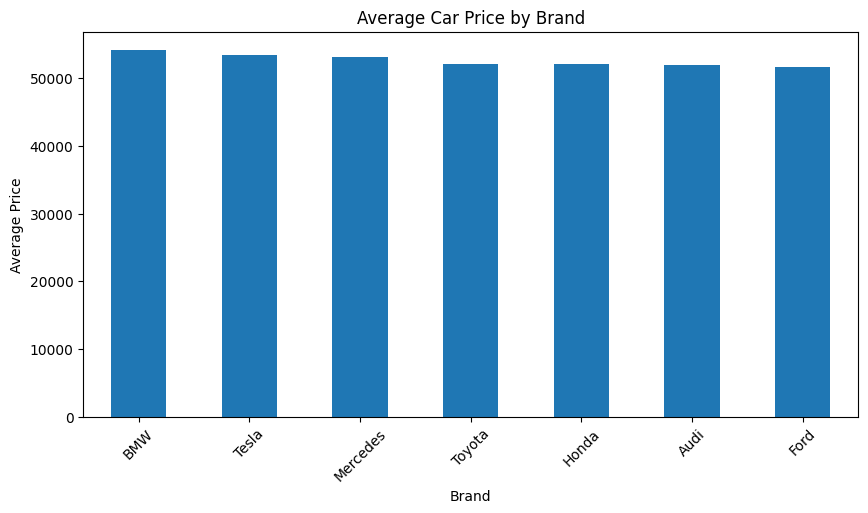

In [96]:
brand_prices = car_df.groupby("Brand")["Price"].mean().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))
brand_prices.plot(kind="bar")
plt.title("Average Car Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

C. Year vs Price

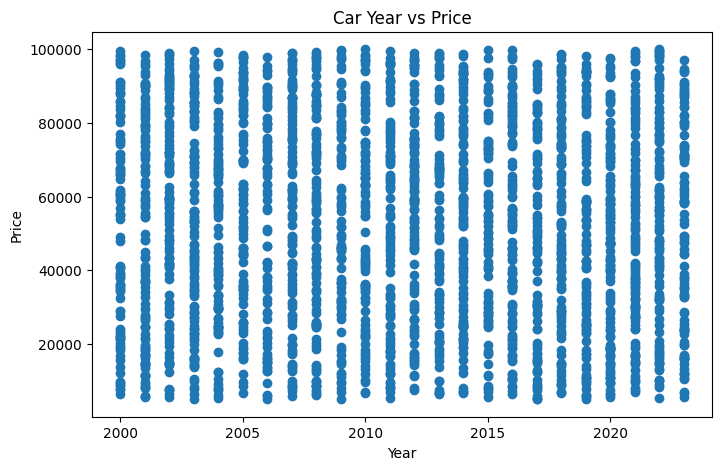

In [97]:
plt.figure(figsize=(8, 5))
plt.scatter(car_df["Year"], car_df["Price"])
plt.title("Car Year vs Price")
plt.xlabel("Year")
plt.ylabel("Price")
plt.show()

D. Mileage vs Price

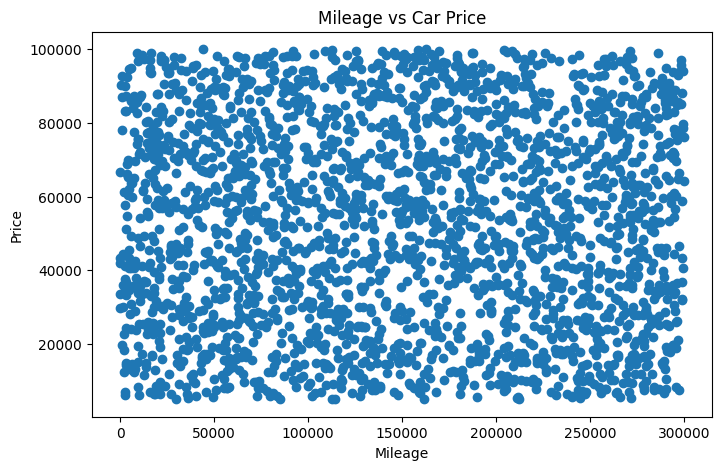

In [98]:
plt.figure(figsize=(8, 5))
plt.scatter(car_df["Mileage"], car_df["Price"])
plt.title("Mileage vs Car Price")
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.show()

E. Average price by fuel type

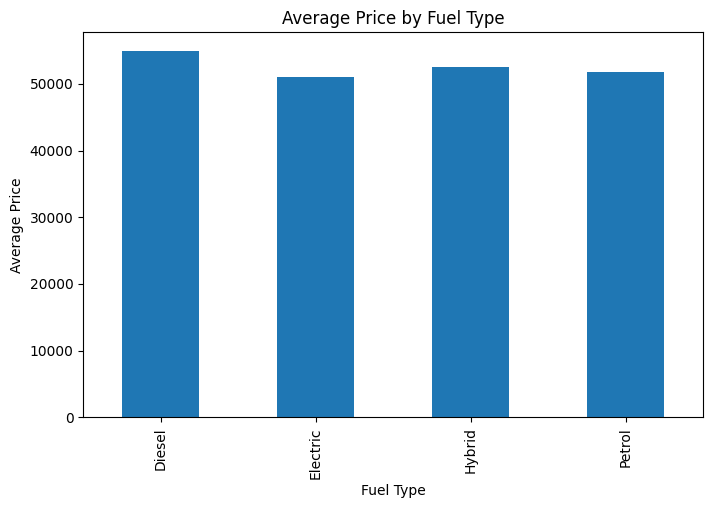

In [99]:
fuel_prices = car_df.groupby("Fuel Type")["Price"].mean()

plt.figure(figsize=(8, 5))
fuel_prices.plot(kind="bar")
plt.title("Average Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Price")
plt.show()

EDA Observations 

- Car prices vary across different brands.
- Manufacturing year and mileage may influence car prices.
- Different fuel types have different average prices.
- The dataset contains numerical and categorical features.
- EDA helps understand patterns and relationships before model training.

6. Data Preprocessing

    A. Import preprocessing libraries

In [100]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

B. Separate features and target

In [101]:
X_car = car_df.drop(
    columns=["Price", "Car ID"]
)

y_car = car_df["Price"]

print("Car Features Shape:", X_car.shape)
print("Car Target Shape:", y_car.shape)

display(X_car.head())

Car Features Shape: (2500, 8)
Car Target Shape: (2500,)


,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Model
0,Tesla,2016,2.3,Petrol,Manual,114832,New,Model X
1,BMW,2018,4.4,Electric,Manual,143190,Used,5 Series
2,Audi,2013,4.5,Electric,Manual,181601,New,A4
3,Tesla,2011,4.1,Diesel,Automatic,68682,New,Model Y
4,Ford,2009,2.6,Diesel,Manual,223009,Like New,Mustang


C. Identify numerical and categorical features

In [102]:
car_numeric = X_car.select_dtypes(
    include=["int64", "float64"]
).columns

car_categorical = X_car.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:", list(car_numeric))
print("Categorical Features:", list(car_categorical))

Numerical Features: ['Year', 'Engine Size', 'Mileage']
Categorical Features: ['Brand', 'Fuel Type', 'Transmission', 'Condition', 'Model']


D. Create preprocessing pipelines

In [104]:
car_numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

car_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

car_preprocessor = ColumnTransformer(
    transformers=[
        ("num", car_numeric_pipeline, list(car_numeric)),
        ("cat", car_categorical_pipeline, list(car_categorical))
    ]
)

print("Car preprocessing pipeline created successfully!")

Car preprocessing pipeline created successfully!


7. Feature Engineering

Feature engineering is the process of creating new useful features from existing dataset columns to improve machine learning performance.

In this project, a new feature called Car_Age is created using the manufacturing year.

In [105]:
car_df["Car_Age"] = 2026 - car_df["Year"]

print("New Feature Created Successfully!")

display(car_df[["Year", "Car_Age", "Price"]].head())

New Feature Created Successfully!


,Year,Car_Age,Price
0,2016,10,26613.92
1,2018,8,14679.61
2,2013,13,44402.61
3,2011,15,86374.33
4,2009,17,73577.10


Feature and Target Separation

In [106]:
X_car = car_df.drop(
    columns=["Price", "Car ID"]
)

y_car = car_df["Price"]

print("Car Features Shape:", X_car.shape)
print("Car Target Shape:", y_car.shape)

Car Features Shape: (2500, 9)
Car Target Shape: (2500,)


Identify numerical and categorical features

In [107]:
car_numeric = X_car.select_dtypes(
    include=["int64", "float64"]
).columns

car_categorical = X_car.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:", list(car_numeric))
print("Categorical Features:", list(car_categorical))

Numerical Features: ['Year', 'Engine Size', 'Mileage', 'Car_Age']
Categorical Features: ['Brand', 'Fuel Type', 'Transmission', 'Condition', 'Model']


Create the preprocessing pipeline

In [108]:
car_numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

car_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

car_preprocessor = ColumnTransformer(
    transformers=[
        ("num", car_numeric_pipeline, list(car_numeric)),
        ("cat", car_categorical_pipeline, list(car_categorical))
    ]
)

print("Car preprocessing pipeline created successfully!")

Car preprocessing pipeline created successfully!


8. Train/Test Split

In [109]:
X_car = car_df.drop(
    columns=["Price", "Car ID"]
)

y_car = car_df["Price"]

X_car_train, X_car_test, y_car_train, y_car_test = train_test_split(
    X_car,
    y_car,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_car_train.shape)
print("Testing Data Shape:", X_car_test.shape)

Training Data Shape: (2000, 9)
Testing Data Shape: (500, 9)


9. Model Selection

Explanation:

Random Forest Regressor is selected for car price prediction.

Reasons for selecting Random Forest:
- It can learn complex relationships between features.
- It combines multiple decision trees.
- It can handle numerical and encoded categorical features.
- It can provide feature importance values.
- It is suitable for regression problems.

10. Model Training

A. Preprocess training and testing data

In [110]:
X_car_train_processed = car_preprocessor.fit_transform(
    X_car_train
)

X_car_test_processed = car_preprocessor.transform(
    X_car_test
)

print("CAR DATASET")
print("Training data shape:", X_car_train_processed.shape)
print("Testing data shape:", X_car_test_processed.shape)

CAR DATASET
Training data shape: (2000, 48)
Testing data shape: (500, 48)


B. Train Random Forest model

In [111]:
from sklearn.ensemble import RandomForestRegressor

car_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

car_model.fit(
    X_car_train_processed,
    y_car_train
)

print("Car Price Prediction Model Trained Successfully!")

Car Price Prediction Model Trained Successfully!


11. Prediction

In [112]:
car_predictions = car_model.predict(
    X_car_test_processed
)

print("First 10 Predicted Car Prices:")
print(car_predictions[:10])

First 10 Predicted Car Prices:
[62682.8291 46731.4253 49195.0766 47379.6314 48987.8307 45605.8919
 51334.4063 46175.9366 53847.4243 53607.6471]


Compare actual and predicted prices

In [113]:
car_comparison = pd.DataFrame({
    "Actual Price": y_car_test.values,
    "Predicted Price": car_predictions
})

display(car_comparison.head(10))

,Actual Price,Predicted Price
0,17494.90,62682.8291
1,75919.94,46731.4253
2,87474.10,49195.0766
3,13522.58,47379.6314
4,77070.57,48987.8307
5,40085.49,45605.8919
6,47196.40,51334.4063
7,58558.94,46175.9366
8,23029.74,53847.4243
9,32351.06,53607.6471


12. Model Evaluation

In [114]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

car_mae = mean_absolute_error(
    y_car_test,
    car_predictions
)

car_mse = mean_squared_error(
    y_car_test,
    car_predictions
)

car_rmse = np.sqrt(car_mse)

car_r2 = r2_score(
    y_car_test,
    car_predictions
)

print("CAR MODEL EVALUATION")
print("MAE:", car_mae)
print("MSE:", car_mse)
print("RMSE:", car_rmse)
print("R2 Score:", car_r2)

CAR MODEL EVALUATION
MAE: 24467.278040799996
MSE: 810006127.1158412
RMSE: 28460.606583764886
R2 Score: -0.06923973877032119


Explanation 

- MAE measures the average absolute prediction error.
- MSE measures the average squared prediction error.
- RMSE measures prediction error in the original price unit.
- R² measures how well the model explains variation in car prices.

13. Hyperparameter Tuning

Explanation 

Hyperparameter tuning is used to find better model settings.

In this project, GridSearchCV is used to test different Random Forest parameters and select the combination with the best cross-validation R² score.

In [115]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(
    X_car_train_processed,
    y_car_train
)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation R2 Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}

Best Cross-Validation R2 Score:
-0.03245506170776117


14. Final Model Selection and Comparison

In [116]:
best_car_model = grid_search.best_estimator_

best_car_predictions = best_car_model.predict(
    X_car_test_processed
)

best_mae = mean_absolute_error(
    y_car_test,
    best_car_predictions
)

best_mse = mean_squared_error(
    y_car_test,
    best_car_predictions
)

best_rmse = np.sqrt(best_mse)

best_r2 = r2_score(
    y_car_test,
    best_car_predictions
)

comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2"],
    "Original Random Forest": [
        car_mae, car_mse, car_rmse, car_r2
    ],
    "Improved Random Forest": [
        best_mae, best_mse, best_rmse, best_r2
    ]
})

display(comparison)

,Metric,Original Random Forest,Improved Random Forest
0,MAE,2.446728e+04,2.401007e+04
1,MSE,8.100061e+08,7.772889e+08
2,RMSE,2.846061e+04,2.787990e+04
3,R2,-6.923974e-02,-2.605173e-02


Explanation 

The original Random Forest model is compared with the tuned Random Forest model.

The tuned model should be selected based on its test-set performance. However, a negative R² score means that further improvement is needed before using the model for reliable real-world predictions.

15. Model Deployment

Explanation:

Model deployment means making a trained machine learning model available for future predictions.

In this project, the trained Random Forest model and preprocessing pipeline are saved using Joblib. They can be loaded later to predict the price of a new car.

A. Save the model and preprocessing pipeline

In [117]:
import joblib

joblib.dump(best_car_model, "car_price_model.pkl")

joblib.dump(car_preprocessor, "car_preprocessor.pkl")

print("Car Price Model Saved Successfully!")

Car Price Model Saved Successfully!


B. Load the saved model

In [118]:
loaded_car_model = joblib.load("car_price_model.pkl")

loaded_car_preprocessor = joblib.load(
    "car_preprocessor.pkl"
)

print("Saved Model Loaded Successfully!")

Saved Model Loaded Successfully!


C. Predict the price of a new car

In [119]:
new_car = pd.DataFrame([{
    "Brand": "Toyota",
    "Year": 2022,
    "Engine Size": 2.0,
    "Fuel Type": "Petrol",
    "Transmission": "Automatic",
    "Mileage": 30000,
    "Condition": "Good",
    "Model": "Camry",
    "Car_Age": 2026 - 2022
}])

new_car_processed = loaded_car_preprocessor.transform(
    new_car
)

new_car_prediction = loaded_car_model.predict(
    new_car_processed
)

print("Predicted Car Price:", new_car_prediction[0])

Predicted Car Price: 53419.64038247724


16. Complete Machine Learning Workflow 


                   PROBLEM DEFINITION
                       |
                       v
              BUSINESS UNDERSTANDING
                       |
                       v
                DATA COLLECTION
                       |
                       v
                DATA UNDERSTANDING
                       |
                       v
          EXPLORATORY DATA ANALYSIS
                       |
                       v
              DATA PREPROCESSING
                       |
                       v
              FEATURE ENGINEERING
                       |
                       v
                TRAIN/TEST SPLIT
                       |
                       v
                 MODEL SELECTION
                       |
                       v
                 MODEL TRAINING
                       |
                       v
                   PREDICTION
                       |
                       v
                MODEL EVALUATION
                       |
                       v
              HYPERPARAMETER TUNING
                       |
                       v
              FINAL MODEL SELECTION
                       |
                       v
                 MODEL DEPLOYMENT

Final Conclusion

The Car Price Prediction project demonstrates a complete machine learning workflow using Python and Scikit-learn.

The workflow includes problem definition, business understanding, data collection, data understanding, exploratory data analysis, preprocessing, feature engineering, train/test splitting, model selection, model training, prediction, evaluation, hyperparameter tuning, and deployment.

A Random Forest Regressor was trained and optimized using GridSearchCV. The model was evaluated using MAE, MSE, RMSE, and R² score.

The project provides practical understanding of the machine learning lifecycle, from raw data to saving a trained model for future predictions.